# **The Birthday Problem**
___

**Probability · Combinatorics · Monte Carlo Simulation**
___

How many people must be present in a room before the probability of a shared birthday exceeds 50%?

The answer is 23, assuming 365 equally likely birthdays and independent birthday assignments. This result is often surprising because it is considerably smaller than the number of days in a year.

The key is that the event does not require a match with any particular person's birthday. A match between any pair in the group is sufficient.

This notebook investigates the result through probability theory and repeated computational experiments. The theoretical probability provides a reference value; the simulation allows us to examine how closely empirical estimates agree with it.

___
## Problem statement

Given (k) people, determine the probability that at least two share the same birthday.

___
## Assumptions

* February 29 is excluded, leaving 365 possible birthdays.
* Each birthday is equally likely.
* Birthday assignments are independent.
* A match occurs when any two or more people share a birthday.

These assumptions define an idealised probability model. Real-world birthday distributions are not perfectly uniform, but the simplified model is sufficient to investigate the central result.


___

## Mathematical model

Calculating the probability of a match directly requires accounting for many overlapping cases: exactly one matching pair, multiple matching pairs, and groups of three or more people sharing a birthday.

It is simpler to calculate the complementary event: **all \(k\) birthdays are different**.

For the first person, all 365 birthdays are available. The second person must avoid the first person's birthday, leaving 364 choices. Each subsequent person must avoid all previously assigned birthdays.

For \(0 \leq k \leq 365\), the probability that no birthdays match is

$$
P(\text{no match}) =
\frac{365}{365}
\cdot
\frac{364}{365}
\cdot
\frac{363}{365}
\cdots
\frac{365-k+1}{365}.
$$

Equivalently,

$$
P(\text{no match}) =
\prod_{i=0}^{k-1}\left(1-\frac{i}{365}\right).
$$

Since a match and no match are complementary events,

$$
\boxed{
P(\text{match}) =
1 -
\prod_{i=0}^{k-1}\left(1-\frac{i}{365}\right)
}
$$

For \(k>365\), a match is guaranteed by the pigeonhole principle.

The expression above gives the theoretical probability under the stated assumptions. The simulation will estimate the same quantity by generating random birthday assignments and recording whether each group contains a match.


___
## **Simulation Code**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import prod

In [2]:
rng = np.random.default_rng(42)  # Set a random seed for reproducibility

___
#### **1. Theoretical probability**

The probability of a birthday match is calculated through the complementary event: no two people share a birthday.

For a group of \(k\) people,

$$
P(\text{match}) =
1-\prod_{i=0}^{k-1}\left(1-\frac{i}{365}\right).
$$

We will implement this expression as a reference calculation. Keeping the theoretical result separate from the simulation allows us to evaluate the accuracy of our empirical estimates.


In [3]:
def birthday_match_probability(k, days=365):
  
    if not isinstance(k, (int, np.integer)) or isinstance(k, (bool, np.bool_)):
        raise TypeError("k must be an integer.")

    if k < 0:
        raise ValueError("k cannot be negative.")

    if k > days:
        return 1.0

    p_no_match = prod(1 - i / days for i in range(k))

    return 1 - p_no_match

#### Checking the theoretical result

In [4]:
group_sizes = [2, 10, 20, 22, 23, 30, 50, 100]

theoretical_results = pd.DataFrame({
    "People": group_sizes,
    "Match Probability": [
        birthday_match_probability(k)
        for k in group_sizes
    ]
})

theoretical_results["Match Probability (%)"] = (
    theoretical_results["Match Probability"] * 100
)

theoretical_results

,People,Match Probability,Match Probability (%)
0,2,0.002740,0.273973
1,10,0.116948,11.694818
2,20,0.411438,41.143838
3,22,0.475695,47.569531
4,23,0.507297,50.729723
5,30,0.706316,70.631624
6,50,0.970374,97.037358
7,100,1.000000,99.999969


---

#### **2. How does group size affect the probability?**

The theoretical probability increases with the number of people, but not at a constant rate.

The curve shows how quickly a birthday match becomes likely as more people enter the group. The 50% reference line helps identify the point at which a match becomes more likely than not.


In [5]:
group_sizes_curve = np.arange(1, 101)

theoretical_probabilities = np.array([
    birthday_match_probability(k)
    for k in group_sizes_curve
])

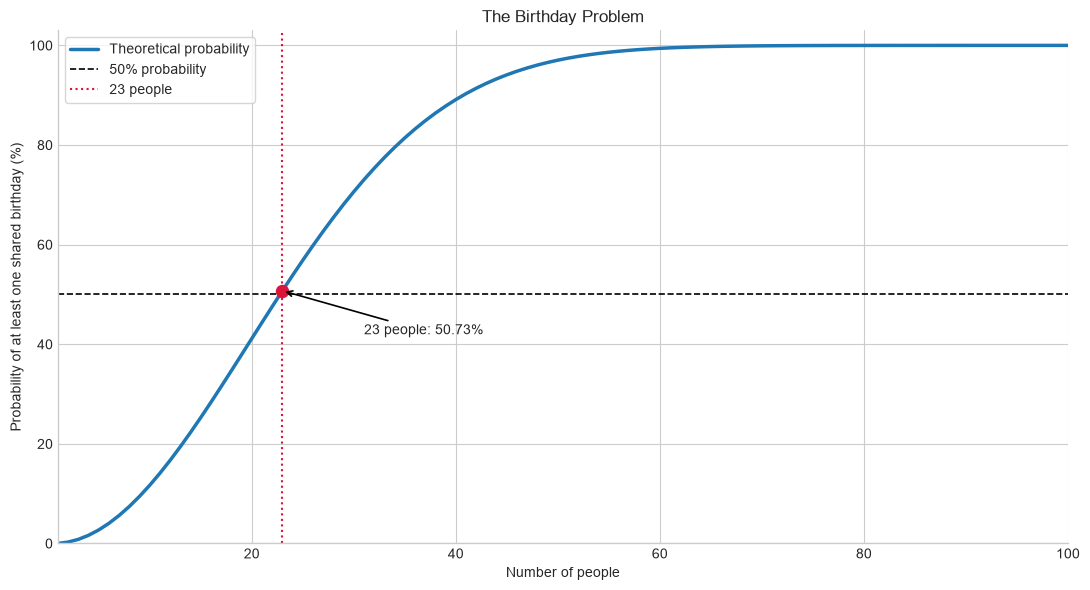

In [6]:
plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    group_sizes_curve,
    theoretical_probabilities * 100,
    linewidth=2.5,
    label="Theoretical probability"
)

ax.axhline(
    50,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="50% probability"
)

ax.axvline(
    23,
    color="crimson",
    linestyle=":",
    linewidth=1.5,
    label="23 people"
)

ax.scatter(
    [23],
    [birthday_match_probability(23) * 100],
    color="crimson",
    s=75,
    zorder=3
)

ax.annotate(
    "23 people: 50.73%",
    xy=(23, birthday_match_probability(23) * 100),
    xytext=(31, 42),
    arrowprops={"arrowstyle": "->", "linewidth": 1.2},
    fontsize=10
)

ax.set(
    title="The Birthday Problem",
    xlabel="Number of people",
    ylabel="Probability of at least one shared birthday (%)",
    xlim=(1, 100),
    ylim=(0, 103)
)

ax.legend(frameon=True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

___
#### **3. Monte Carlo simulation**

The theoretical model predicts a 50.73% probability of at least one shared birthday among 23 people.

To examine this result computationally, we generate random birthday assignments and check whether each group contains a duplicate.

Each generated group represents one experiment:

* **Success:** At least two people share a birthday.
* **Failure:** Every person has a different birthday.

Repeating the experiment allows us to estimate the probability from the observed proportion of successful trials.


In [7]:
k = 23
days = 365

birthdays = rng.integers(
    low=0,
    high=days,
    size=k
)

birthdays

array([ 32, 282, 238, 160, 158, 313,  31, 254,  73,  34, 192, 356, 268,
       277, 261, 286, 187,  46, 306, 164, 182, 135,  66])

In [8]:
has_match = len(np.unique(birthdays)) < k

has_match

False

___
#### **4. Estimating the probability**

A single experiment produces only one binary outcome. It cannot provide a reliable estimate of the probability of a birthday match.

We therefore repeat the experiment many times, recording whether each generated group contains at least one duplicate birthday.

The estimated probability is the proportion of successful experiments:

$$
\hat{p}=\frac{\text{Successful trials}}{\text{Total trials}}.
$$

As the number of independent trials increases, the estimate generally becomes more stable around the theoretical probability.


In [9]:
n_simulations = 10_000

birthday_groups = rng.integers(
    low=0,
    high=days,
    size=(n_simulations, k)
)

birthday_groups.shape

(10000, 23)

In [10]:
has_matches = (
    np.apply_along_axis(
        lambda group: len(np.unique(group)) < k,
        axis=1,
        arr=birthday_groups
    )
)

simulated_probability = has_matches.mean()

simulated_probability

np.float64(0.4992)

In [11]:
theoretical_probability = birthday_match_probability(k)

simulation_results = pd.DataFrame({
    "Metric": [
        "Number of people",
        "Number of simulations",
        "Successful experiments",
        "Theoretical probability",
        "Simulated probability",
        "Absolute difference"
    ],
    "Value": [
        k,
        n_simulations,
        int(has_matches.sum()),
        theoretical_probability,
        simulated_probability,
        abs(simulated_probability - theoretical_probability)
    ]
})

simulation_results

,Metric,Value
0,Number of people,23.000000
1,Number of simulations,10000.000000
2,Successful experiments,4992.000000
3,Theoretical probability,0.507297
4,Simulated probability,0.499200
5,Absolute difference,0.008097


___
#### **5. Simulation versus theory**

The empirical probability is estimated from the fraction of simulated groups containing at least one birthday match.
Comparing this estimate with the theoretical probability allows us to assess whether the simulation reproduces the expected behaviour.
The comparison concerns the probability of a match across repeated groups, not the number of matching pairs within any single group.


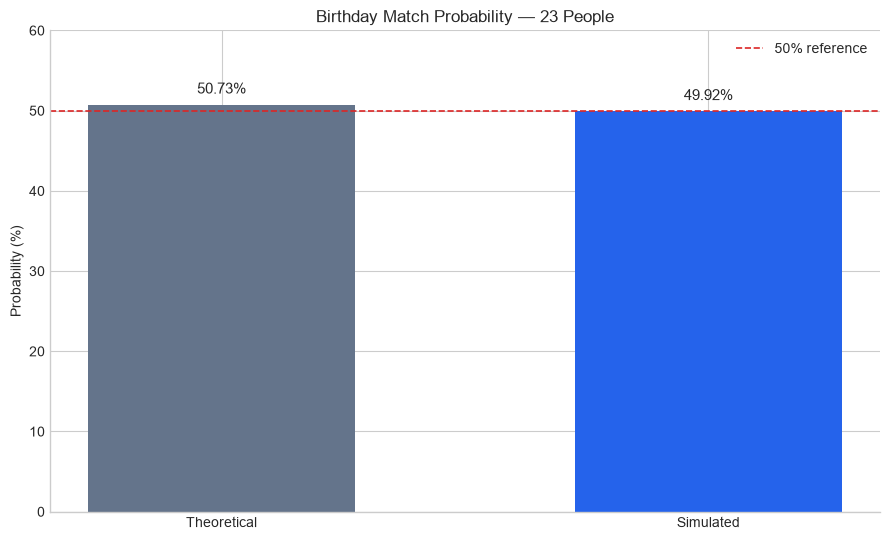

In [12]:
fig, ax = plt.subplots(figsize=(9, 5.5))

labels = ["Theoretical", "Simulated"]
values = [
    theoretical_probability * 100,
    simulated_probability * 100
]

bars = ax.bar(
    labels,
    values,
    width=0.55,
    color=["#64748b", "#2563eb"]
)

ax.axhline(
    50,
    color="#dc2626",
    linestyle="--",
    linewidth=1.2,
    label="50% reference"
)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set(
    title=f"Birthday Match Probability — {k} People",
    ylabel="Probability (%)",
    ylim=(0, 60)
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend()
plt.tight_layout()
plt.show()

___
#### **6. How does the estimate change with more simulations?**

The empirical probability is calculated from a finite collection of random experiments. Its value depends on the particular outcomes observed.

Increasing the number of trials generally reduces the sampling variability of the estimated probability. However, the estimate does not have to move steadily towards the theoretical value: it may move closer or farther away as additional trials are observed.

This experiment examines how the estimate behaves as the number of simulated groups increases.


In [13]:
n_simulations = 50_000

birthday_groups = rng.integers(
    low=0,
    high=days,
    size=(n_simulations, k)
)

has_matches = np.apply_along_axis(
    lambda group: len(np.unique(group)) < k,
    axis=1,
    arr=birthday_groups
)

cumulative_estimates = (
    np.cumsum(has_matches) /
    np.arange(1, n_simulations + 1)
)

In [14]:
checkpoints = [100, 500, 1_000, 5_000, 10_000, 50_000]

convergence_results = pd.DataFrame({
    "Simulations": checkpoints,
    "Estimated Probability": [
        cumulative_estimates[n - 1]
        for n in checkpoints
    ]
})

convergence_results["Estimated Probability (%)"] = (
    convergence_results["Estimated Probability"] * 100
)

convergence_results["Theoretical Probability (%)"] = (
    theoretical_probability * 100
)

convergence_results

,Simulations,Estimated Probability,Estimated Probability (%),Theoretical Probability (%)
0,100,0.61000,61.000,50.729723
1,500,0.52200,52.200,50.729723
2,1000,0.52400,52.400,50.729723
3,5000,0.51240,51.240,50.729723
4,10000,0.51870,51.870,50.729723
5,50000,0.50988,50.988,50.729723


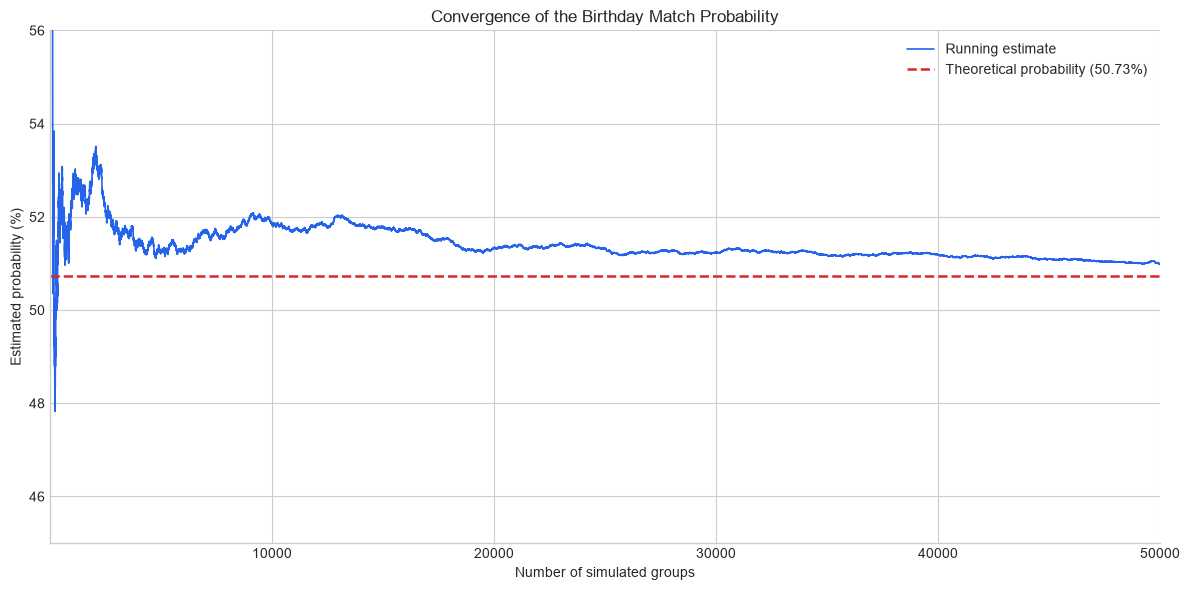

In [15]:
fig, ax = plt.subplots(figsize=(12, 6))

trial_numbers = np.arange(1, n_simulations + 1)

ax.plot(
    trial_numbers,
    cumulative_estimates * 100,
    color="#2563eb",
    linewidth=1.2,
    label="Running estimate"
)

ax.axhline(
    theoretical_probability * 100,
    color="#dc2626",
    linestyle="--",
    linewidth=1.8,
    label=f"Theoretical probability ({theoretical_probability:.2%})"
)

ax.set(
    title="Convergence of the Birthday Match Probability",
    xlabel="Number of simulated groups",
    ylabel="Estimated probability (%)",
    xlim=(1, n_simulations),
    ylim=(45, 56)
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend()
plt.tight_layout()
plt.show()

#### **Interpretation**

The simulation illustrates the relationship between the number of independent trials and the variability of an empirical probability estimate.

A larger number of trials generally produces a more stable estimate, although random fluctuations remain possible.

The theoretical probability is approximately 50.73%. The empirical estimate is not expected to equal this value exactly in a finite simulation.

This distinction is fundamental to Monte Carlo methods: the theoretical model defines the probability being investigated, while repeated random experiments provide an estimate of that probability.


___
#### **7. Probability across group sizes**

The birthday problem becomes more interesting when the number of people is varied.

For each group size, we estimate the probability of at least one shared birthday by generating independent groups and recording the proportion containing a match.

We then compare the empirical estimates with the theoretical probabilities.

Agreement across a range of group sizes provides a more informative check of the simulation than examining a single group size alone.


In [16]:
group_sizes = np.arange(2, 101)
n_simulations_per_size = 10_000

simulation_probabilities = []

for group_size in group_sizes:
    birthday_groups = rng.integers(
        low=0,
        high=days,
        size=(n_simulations_per_size, group_size)
    )

    has_matches = np.any(
        np.diff(np.sort(birthday_groups, axis=1), axis=1) == 0,
        axis=1
    )

    simulation_probabilities.append(has_matches.mean())

simulation_probabilities = np.array(simulation_probabilities)

theoretical_probabilities = np.array([
    birthday_match_probability(k)
    for k in group_sizes
])

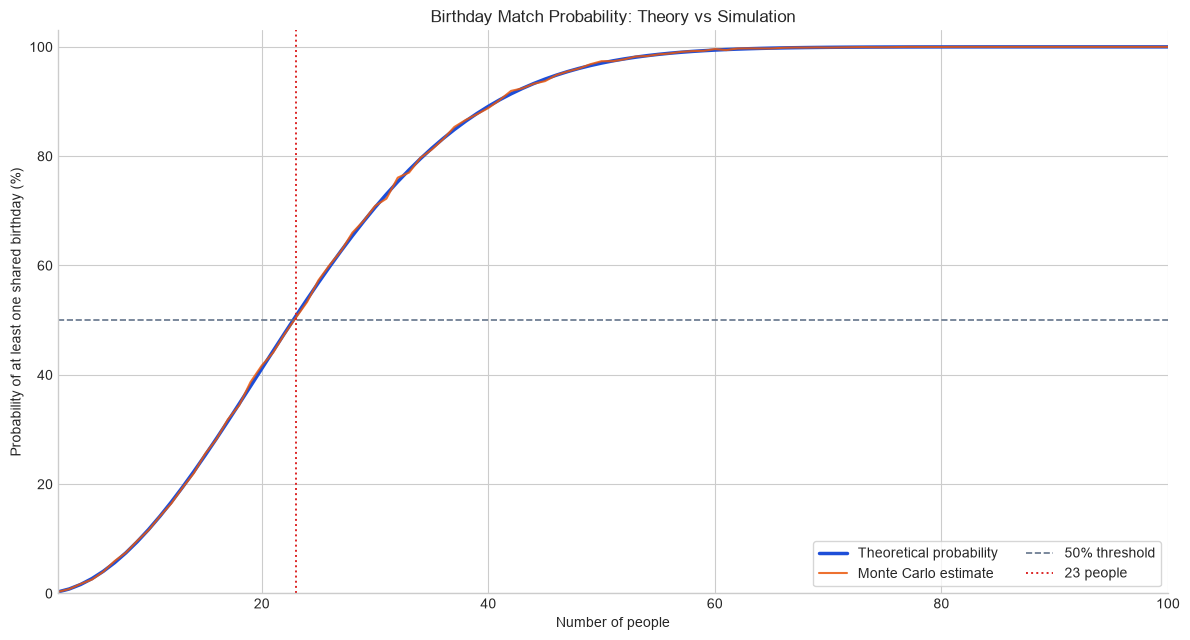

In [17]:
fig, ax = plt.subplots(figsize=(12, 6.5))

ax.plot(
    group_sizes,
    theoretical_probabilities * 100,
    linewidth=2.5,
    color="#1d4ed8",
    label="Theoretical probability"
)

ax.plot(
    group_sizes,
    simulation_probabilities * 100,
    linewidth=1.5,
    color="#ea580c",
    alpha=0.85,
    label="Monte Carlo estimate"
)

ax.axhline(
    50,
    color="#64748b",
    linestyle="--",
    linewidth=1.2,
    label="50% threshold"
)

ax.axvline(
    23,
    color="#dc2626",
    linestyle=":",
    linewidth=1.4,
    label="23 people"
)

ax.set(
    title="Birthday Match Probability: Theory vs Simulation",
    xlabel="Number of people",
    ylabel="Probability of at least one shared birthday (%)",
    xlim=(2, 100),
    ylim=(0, 103)
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend(ncol=2, frameon=True)
plt.tight_layout()
plt.show()

The simulated curve follows the theoretical curve.

The simulated line fluctuate around the theoretical result because each group size uses a finite number of random experiments. We should also see the probability rise rapidly as the group size increases.

The 50% threshold is crossed at approximately 23 people.

This chart brings together the mathematical model and the computational experiment.

___
#### **8. Why do matches become likely so quickly?**

For a group of \(k\) people, the number of distinct pairs is

$$
\binom{k}{2}=\frac{k(k-1)}{2}.
$$

Each pair represents a possible birthday comparison.

As the group grows, the number of pairs increases approximately quadratically rather than linearly. Consequently, even a relatively small group creates many opportunities for a birthday match.

The number of pairs does not directly equal the probability of a match. Pairwise matching events can overlap, so the exact probability must account for those overlaps. The complement formula provides that exact result.


In [18]:
pair_counts = pd.DataFrame({
    "People": group_sizes,
    "Possible Pairs": group_sizes * (group_sizes - 1) // 2,
    "Theoretical Match Probability": theoretical_probabilities
})

pair_counts["Match Probability (%)"] = (
    pair_counts["Theoretical Match Probability"] * 100
)

pair_counts.loc[
    pair_counts["People"].isin([5, 10, 15, 20, 23, 30, 50, 100]),
    ["People", "Possible Pairs", "Match Probability (%)"]
]

,People,Possible Pairs,Match Probability (%)
3,5,10,2.713557
8,10,45,11.694818
13,15,105,25.290132
18,20,190,41.143838
21,23,253,50.729723
28,30,435,70.631624
48,50,1225,97.037358
98,100,4950,99.999969


The number of possible pairs increases rapidly, and the probability of a match increases alongside it.

However, remember that 253 pairs do not represent 253 independent trials. We use the pair count to develop intuition, not as a substitute for the probability formula.




___


**Plotting the growth in possible pairs**

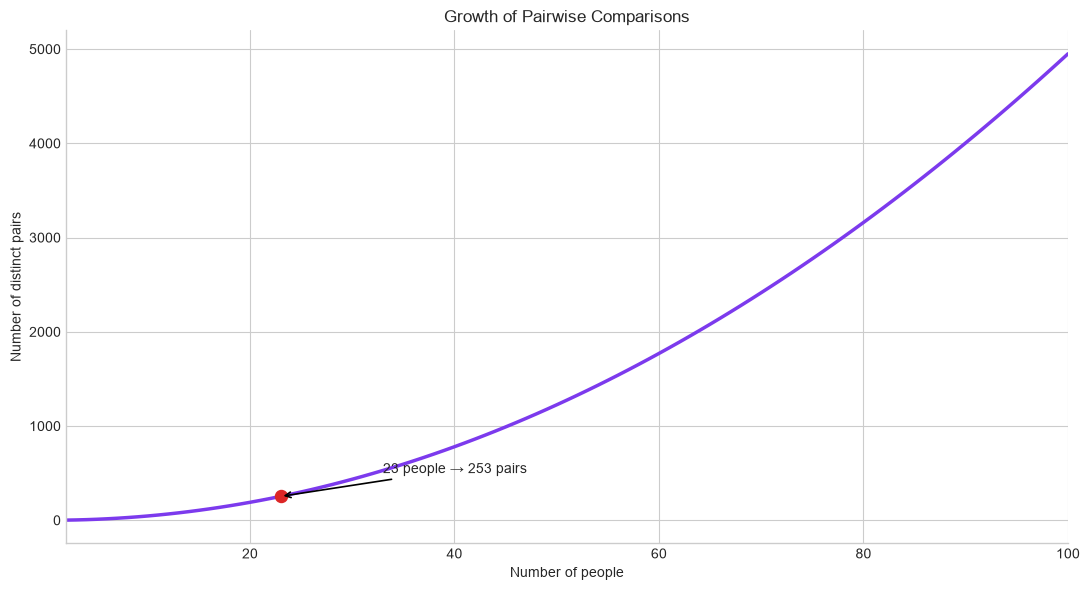

In [19]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    group_sizes,
    group_sizes * (group_sizes - 1) / 2,
    color="#7c3aed",
    linewidth=2.5
)

ax.scatter(
    [23],
    [23 * 22 / 2],
    color="#dc2626",
    s=75,
    zorder=3
)

ax.annotate(
    "23 people → 253 pairs",
    xy=(23, 253),
    xytext=(33, 500),
    arrowprops={"arrowstyle": "->", "linewidth": 1.2},
    fontsize=10
)

ax.set(
    title="Growth of Pairwise Comparisons",
    xlabel="Number of people",
    ylabel="Number of distinct pairs",
    xlim=(2, 100)
)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

This graph illustrates the quadratic growth in the number of possible pairs.

It's not a probability plot; it shows the number of comparisons that could potentially produce a match.

___
#### **9. What did we learn?**

The birthday problem shows how quickly the probability of a match increases as the number of people grows.

A group of just 23 people has approximately a 50.73% chance of containing at least one shared birthday. With 50 people, the probability rises to approximately 97.04%.

Our simulations produced results close to the theoretical probabilities. The small differences are expected because each simulation uses a finite number of randomly generated groups.

The number of possible pairs also increases rapidly with group size. For 23 people, there are 253 distinct pairs whose birthdays could match. This helps explain why a match becomes likely even when the group is much smaller than 365 people.

The important distinction is that the number of pairs explains the intuition, while the complement rule gives us the exact probability under our assumptions.


___
#### **10. Limitations**

This simulation assumes that all 365 birthdays are equally likely and that each person's birthday is independent of everyone else's.

Real-world birthdays do not follow a perfectly uniform distribution. Seasonal birth patterns and other factors can affect the actual distribution.

The simulation also uses randomly generated birthdays rather than real population data. Its purpose is to examine the mathematical model, not to estimate birthday patterns in a particular country or population.


___

Thanks for reading.

- Abdur Rahman (Rahven)